# E-Commerce Customer Behavior & Purchase Patterns Analysis

**Objective:** Analyze customer behavior and purchase patterns to understand how app usage, website usage, session length, and membership duration relate to yearly customer spending.

**Dataset file:** `ecommerce_customers.csv`  
**Important:** Keep this CSV in the same folder as this notebook. The notebook uses a relative path.

## Final analysis questions

### Univariate questions
1. What is the distribution of customers' yearly amount spent?
2. What is the typical average session length, and is its distribution skewed?
3. How is the length of customer membership distributed?

### Bivariate questions
4. Is time spent on the mobile app related to yearly amount spent?
5. Is time spent on the website related to yearly amount spent?
6. Is length of membership related to yearly amount spent?

### Additional business questions
7. Do customers who spend more time on the app or website tend to spend more yearly? Which channel has the stronger relationship with spending?
8. Who are the 10 highest-spending customers in this dataset?

**Note:** The dataset contains customer-level information and yearly spending, not individual order histories. Therefore, this analysis studies customer behavior and spending patterns; it cannot identify individual products purchased or exact purchase dates.


## Step 1 — Basic analysis

We will load the CSV, inspect its dimensions, column names, data types, sample records, and descriptive statistics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Keep ecommerce_customers.csv in the same folder as this notebook.
df = pd.read_csv("./ecommerce_customers.csv")

print("Dataset loaded successfully.")
print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

preview_cols = [col for col in df.columns if col not in ["Email", "Address"]]
display(df[preview_cols].head())
print(f"Interpretation: The dataset contains {len(df):,} customer records and {len(df.columns)} columns.")

Dataset loaded successfully.
Shape (rows, columns): (500, 8)

Column names:
['Email', 'Address', 'Avatar', 'Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership', 'Yearly Amount Spent']


,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


Interpretation: The dataset contains 500 customer records and 8 columns.


In [2]:
print("Dataset information:")
df.info()
print(f"Interpretation: The dataset has {len(df):,} rows and {df.shape[1]} columns; {df.select_dtypes(include=np.number).shape[1]} columns are numeric and {df.isna().sum().sum()} values are missing.")

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 69.3 KB
Interpretation: The dataset has 500 rows and 8 columns; 5 columns are numeric and 0 values are missing.


In [3]:
safe_df = df.drop(columns=["Email", "Address"], errors="ignore")
display(safe_df.describe(include="all").T)
print("Interpretation: This table summarizes numeric fields and non-contact categories. Email and full address values are excluded from the displayed summary.")

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Avatar,500,138,Cyan,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Avg. Session Length,500.0,NaN,NaN,NaN,33.053194,0.992563,29.532429,32.341822,33.082008,33.711985,36.139662
Time on App,500.0,NaN,NaN,NaN,12.052488,0.994216,8.508152,11.388153,11.983231,12.75385,15.126994
Time on Website,500.0,NaN,NaN,NaN,37.060445,1.010489,33.913847,36.349257,37.069367,37.716432,40.005182
Length of Membership,500.0,NaN,NaN,NaN,3.533462,0.999278,0.269901,2.93045,3.533975,4.126502,6.922689
Yearly Amount Spent,500.0,NaN,NaN,NaN,499.314038,79.314782,256.670582,445.038277,498.887875,549.313828,765.518462


Interpretation: This table summarizes numeric fields and non-contact categories. Email and full address values are excluded from the displayed summary.


### Column meanings

| Column | Meaning |
|---|---|
| Email | Customer email address; used as a customer identifier |
| Address | Customer address |
| Avatar | Customer avatar/color label |
| Avg. Session Length | Average duration of a customer session; the time unit is not specified in the CSV |
| Time on App | Average app engagement duration; the time unit is not specified in the CSV |
| Time on Website | Average website engagement duration; the time unit is not specified in the CSV |
| Length of Membership | Customer membership duration; the unit is not specified in the CSV |
| Yearly Amount Spent | Amount spent by the customer in a year |

The first three fields identify or describe the customer. The remaining five fields are numeric behavior and spending measures.

## Step 2 — Missing values

First, count missing values in each column. Numeric columns are filled with their median, while missing non-contact categories are labeled `Unknown`. Email and Address are not imputed: inventing contact details with a mode would create misleading customer records. The median is less affected by extreme values than the mean, and the code reports how many values were filled.

In [4]:
missing_before = df.isna().sum().sort_values(ascending=False)
display(missing_before.to_frame("Missing values"))

df_clean = df.copy()

numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [
    col for col in df_clean.select_dtypes(exclude=np.number).columns
    if col not in ["Email", "Address"]
]
filled_numeric = 0
filled_categorical = 0

for col in numeric_cols:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())
        filled_numeric += int(df[col].isna().sum())

for col in categorical_cols:
    if df_clean[col].isna().any():
        mode_values = df_clean[col].mode(dropna=True)
        if not mode_values.empty:
            df_clean[col] = df_clean[col].fillna(mode_values.iloc[0])
            filled_categorical += int(df[col].isna().sum())

print("Missing values after handling:")
display(df_clean.isna().sum().to_frame("Missing values after"))
contact_missing = int(df_clean[[col for col in ["Email", "Address"] if col in df_clean.columns]].isna().sum().sum())
print(f"Filled {filled_numeric} numeric and {filled_categorical} non-contact categorical values.")
print(f"Interpretation: Email and Address values were not imputed; {contact_missing} contact-field values remain missing for review.")

,Missing values
Email,0
Address,0
Avatar,0
Avg. Session Length,0
Time on App,0
Time on Website,0
Length of Membership,0
Yearly Amount Spent,0


Missing values after handling:


,Missing values after
Email,0
Address,0
Avatar,0
Avg. Session Length,0
Time on App,0
Time on Website,0
Length of Membership,0
Yearly Amount Spent,0


Filled 0 numeric and 0 non-contact categorical values.
Interpretation: Email and Address values were not imputed; 0 contact-field values remain missing for review.


**Interpretation:** Numeric gaps use column medians and non-contact categorical gaps use the mode. Email and Address are never imputed; their missing values remain visible for follow-up.

## Step 3 — Repeated values and duplicates

We will count exact duplicate rows and check repeated customer email addresses. If duplicates exist, exact duplicate rows are removed first; repeated emails are then checked separately because they may represent repeated records for the same customer.

In [5]:
exact_duplicates = int(df_clean.duplicated().sum())
print("Exact duplicate rows:", exact_duplicates)
df_clean = df_clean.drop_duplicates().copy()

if "Email" in df_clean.columns:
    email_groups = df_clean[df_clean["Email"].notna()].groupby("Email", sort=False)
    repeated_groups = [group for _, group in email_groups if len(group) > 1]
    repeated_email_rows = sum(len(group) for group in repeated_groups)
    conflicting_groups = sum(
        group.drop(columns="Email").nunique(dropna=False).gt(1).any()
        for group in repeated_groups
    )
    print("Repeated-email groups after exact duplicate removal:", len(repeated_groups))
    print("Rows in repeated-email groups:", repeated_email_rows)
    print("Repeated-email groups with differing customer details:", conflicting_groups)
    print("Repeated-email records are retained for review; only exact duplicate rows were removed.")
else:
    repeated_email_rows = None
    print("Email column not found; customer repetition cannot be checked using email.")

print("Shape after duplicate handling:", df_clean.shape)
print(f"Interpretation: Removed {exact_duplicates} exact duplicate rows. Repeated emails were checked, not automatically treated as duplicate customers.")

Exact duplicate rows: 0


Repeated-email groups after exact duplicate removal: 0
Rows in repeated-email groups: 0
Repeated-email groups with differing customer details: 0
Repeated-email records are retained for review; only exact duplicate rows were removed.
Shape after duplicate handling: (500, 8)
Interpretation: Removed 0 exact duplicate rows. Repeated emails were checked, not automatically treated as duplicate customers.


**Interpretation:** Exact duplicate rows are removed. Repeated emails with potentially different customer details are reported and retained for review rather than silently discarding a record.

## Step 4 — Outlier analysis

We will draw box plots and histograms for every numeric column. Then we will apply the IQR rule to at least two key columns: `Yearly Amount Spent` and `Length of Membership`. Outliers will be retained unless there is evidence that they are data-entry errors; unusually high spending or long membership can be genuine customer behavior.

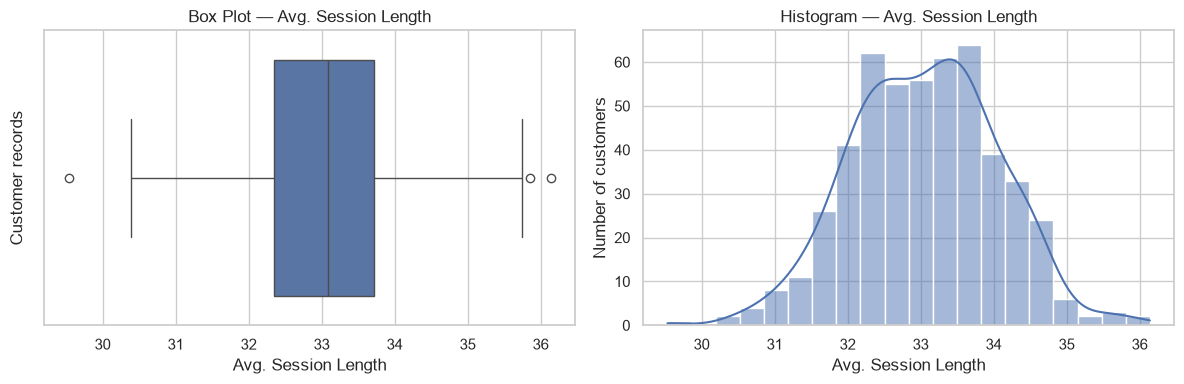

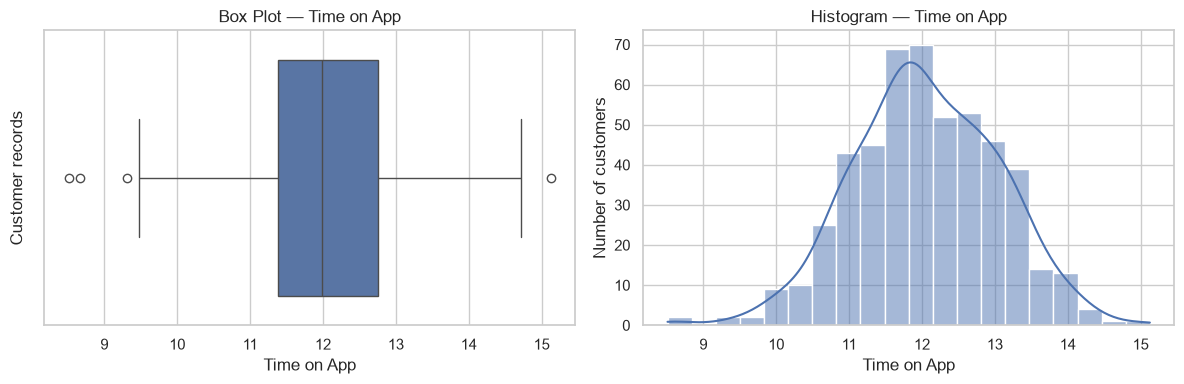

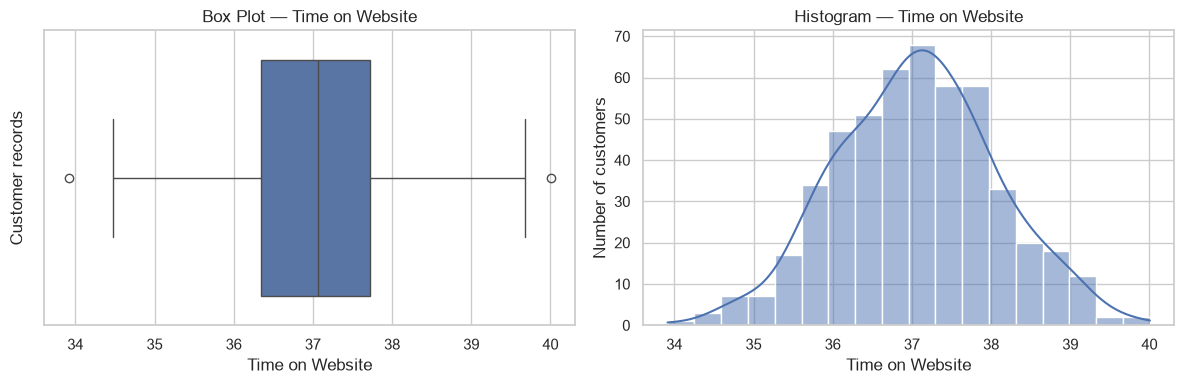

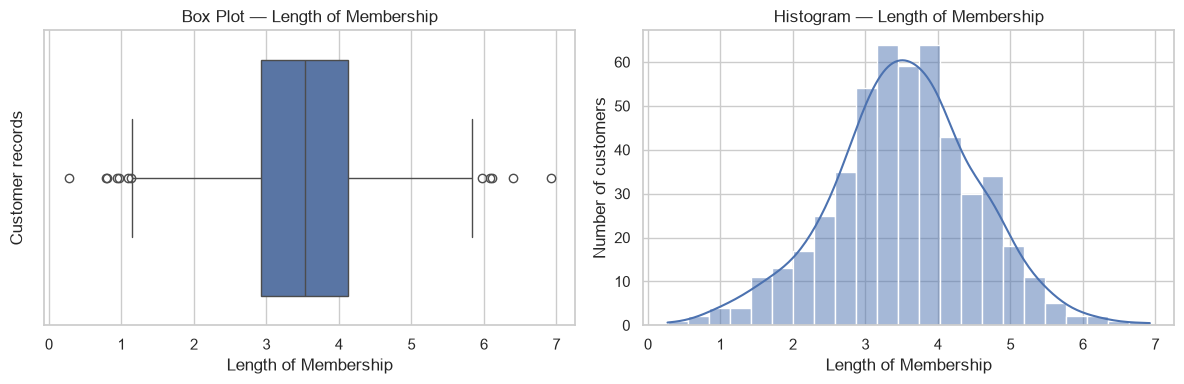

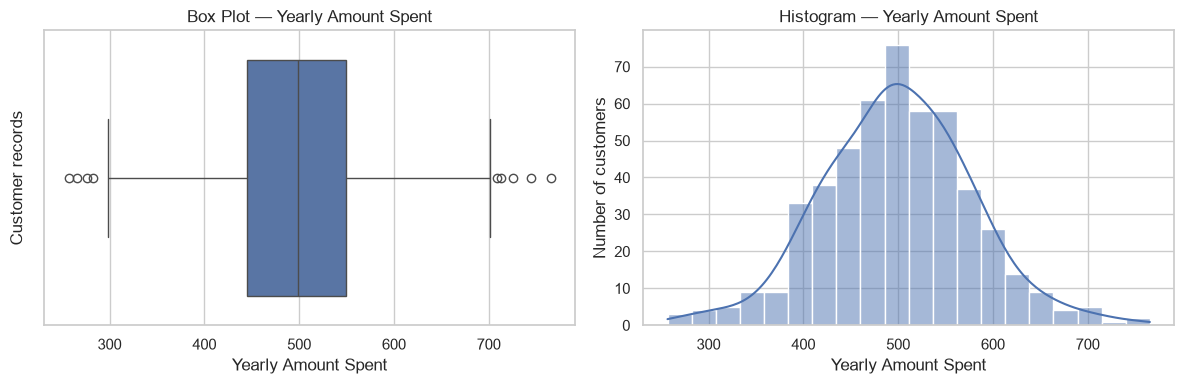

In [6]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(x=df_clean[col], ax=axes[0])
    axes[0].set_title(f"Box Plot — {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Customer records")

    sns.histplot(df_clean[col], kde=True, ax=axes[1])
    axes[1].set_title(f"Histogram — {col}")
    axes[1].set_xlabel(col)
    axes[1].set_ylabel("Number of customers")

    plt.tight_layout()
    plt.show()

In [7]:
def iqr_outlier_report(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = data[(data[column] < lower) | (data[column] > upper)]

    print(f"Column: {column}")
    print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
    print(f"Lower bound: {lower:.2f} | Upper bound: {upper:.2f}")
    print(f"Outlier count: {len(outliers)}")
    print(f"Interpretation: {len(outliers)} values are outside the IQR fences for {column}; they are flagged for review, not automatically removed.")
    print("-" * 55)

for col in ["Yearly Amount Spent", "Length of Membership"]:
    if col in df_clean.columns:
        iqr_outlier_report(df_clean, col)
    else:
        print(f"Column not found: {col}")

Column: Yearly Amount Spent
Q1: 445.04 | Q3: 549.31 | IQR: 104.28
Lower bound: 288.62 | Upper bound: 705.73
Outlier count: 9
Interpretation: 9 values are outside the IQR fences for Yearly Amount Spent; they are flagged for review, not automatically removed.
-------------------------------------------------------
Column: Length of Membership
Q1: 2.93 | Q3: 4.13 | IQR: 1.20
Lower bound: 1.14 | Upper bound: 5.92
Outlier count: 12
Interpretation: 12 values are outside the IQR fences for Length of Membership; they are flagged for review, not automatically removed.
-------------------------------------------------------


**Decision:** We keep the IQR-flagged observations for the main analysis because high spending or long membership may be genuine customer characteristics. IQR identifies unusually distant values; it does not prove that a value is incorrect. We would remove a value only after confirming a data-entry or measurement error.

## Step 5 — Univariate analysis

For each numeric column, we will show a histogram and box plot. Use the median as the typical value when a distribution is skewed; compare mean and median to help identify skewness.

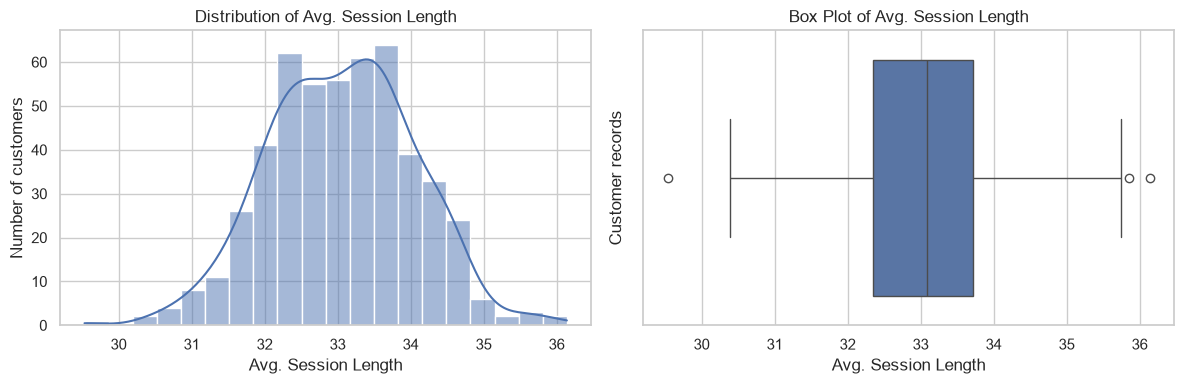

Avg. Session Length: mean = 33.05, median = 33.08, skewness = -0.03.
Interpretation: A typical customer has avg. session length of 33.08; values are approximately symmetric, so the median is a useful center.



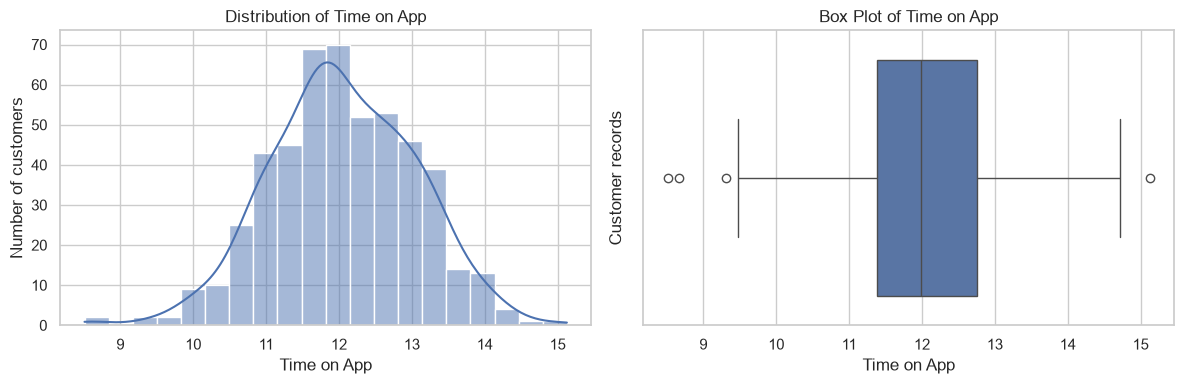

Time on App: mean = 12.05, median = 11.98, skewness = -0.09.
Interpretation: A typical customer has time on app of 11.98; values are approximately symmetric, so the median is a useful center.



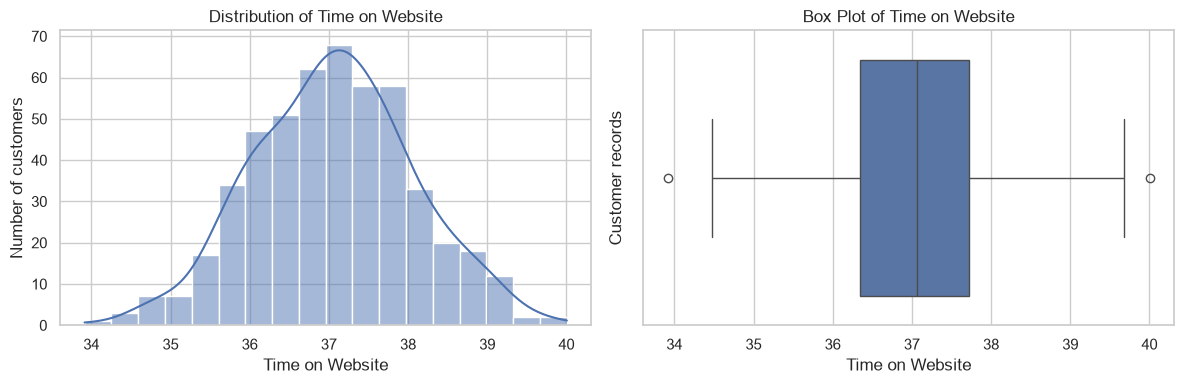

Time on Website: mean = 37.06, median = 37.07, skewness = 0.01.
Interpretation: A typical customer has time on website of 37.07; values are approximately symmetric, so the median is a useful center.



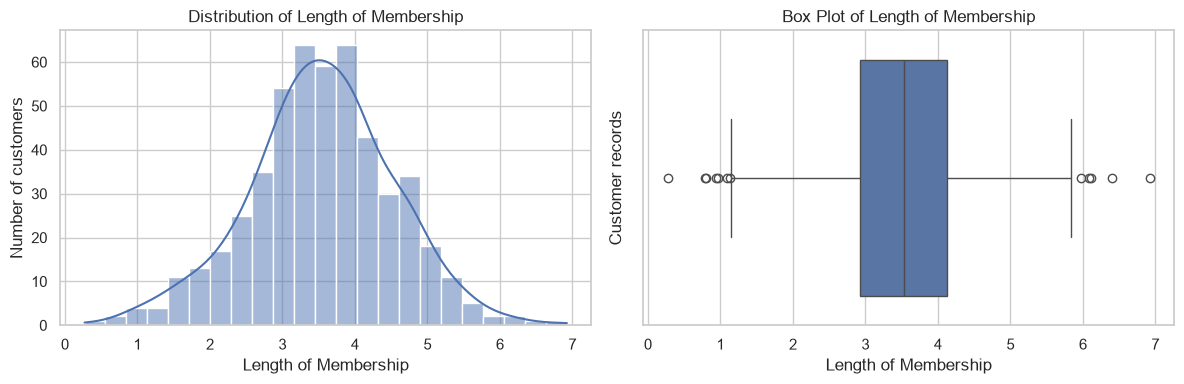

Length of Membership: mean = 3.53, median = 3.53, skewness = -0.11.
Interpretation: A typical customer has length of membership of 3.53; values are approximately symmetric, so the median is a useful center.



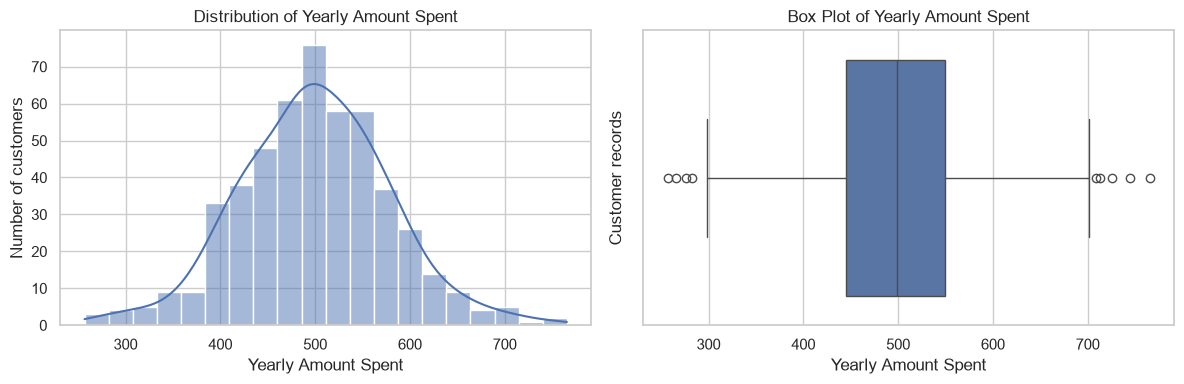

Yearly Amount Spent: mean = 499.31, median = 498.89, skewness = 0.03.
Interpretation: A typical customer has yearly amount spent of 498.89; values are approximately symmetric, so the median is a useful center.



In [8]:
for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df_clean[col], kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Number of customers")

    sns.boxplot(x=df_clean[col], ax=axes[1])
    axes[1].set_title(f"Box Plot of {col}")
    axes[1].set_xlabel(col)
    axes[1].set_ylabel("Customer records")

    plt.tight_layout()
    plt.show()

    mean_value = df_clean[col].mean()
    median_value = df_clean[col].median()
    skew_value = df_clean[col].skew()
    skew_label = "right-skewed" if skew_value > 0.5 else "left-skewed" if skew_value < -0.5 else "approximately symmetric"
    print(f"{col}: mean = {mean_value:.2f}, median = {median_value:.2f}, skewness = {skew_value:.2f}.")
    print(f"Interpretation: A typical customer has {col.lower()} of {median_value:.2f}; values are {skew_label}, so the median is a useful center.\n")

## Step 6 — Bivariate analysis

We will examine relationships between app time, website time, membership length, and yearly spending. A correlation heatmap summarizes linear relationships between numeric variables.

In [9]:
required_cols = ["Time on App", "Time on Website", "Length of Membership", "Yearly Amount Spent"]
missing_required = [col for col in required_cols if col not in df_clean.columns]

if not missing_required:
    print("The question-specific scatter plots below show the app, website, and membership relationships with yearly spending.")
else:
    print("Required columns not found:", missing_required)

The question-specific scatter plots below show the app, website, and membership relationships with yearly spending.


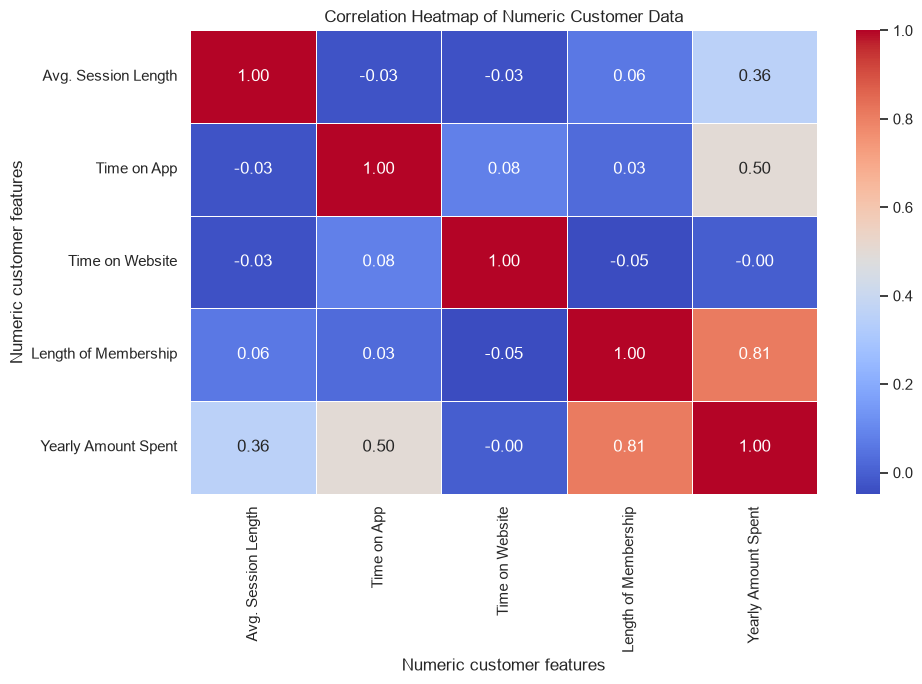

,Correlation with yearly amount spent
Length of Membership,0.809084
Time on App,0.499328
Avg. Session Length,0.355088
Time on Website,-0.002641


Interpretation: Length of Membership has the strongest linear association with yearly spending (r = 0.809); this is an association, not proof of cause.


In [10]:
corr = df_clean.select_dtypes(include=np.number).corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Customer Data")
plt.xlabel("Numeric customer features")
plt.ylabel("Numeric customer features")
plt.tight_layout()
plt.show()

def describe_correlation(value):
    if pd.isna(value):
        return "cannot be determined because the correlation is undefined"
    magnitude = abs(value)
    if magnitude < 0.1:
        return "little to no linear association"
    strength = "strong" if magnitude >= 0.7 else "moderate" if magnitude >= 0.4 else "weak"
    direction = "positive" if value > 0 else "negative"
    return f"a {strength} {direction} linear association"

if "Yearly Amount Spent" in corr.columns:
    spending_corr = corr["Yearly Amount Spent"].drop("Yearly Amount Spent").sort_values(key=abs, ascending=False)
    display(spending_corr.to_frame("Correlation with yearly amount spent"))
    if not spending_corr.empty:
        strongest = spending_corr.index[0]
        strongest_r = spending_corr.iloc[0]
        print(f"Interpretation: {strongest} has the strongest linear association with yearly spending (r = {strongest_r:.3f}); this is an association, not proof of cause.")

**Interpretation:** Read the scatter plots for direction and spread. In the heatmap, values closer to +1 indicate stronger positive linear relationships, values closer to -1 indicate stronger negative relationships, and values near 0 indicate weak linear relationships. The app-versus-website comparison uses absolute correlation strength; it does not establish causation.

## Step 7 — Answer the analysis questions

Each question below is answered using a graph, table, or calculated statistic. The results are generated from the loaded dataset, so the written outputs update when the CSV changes.

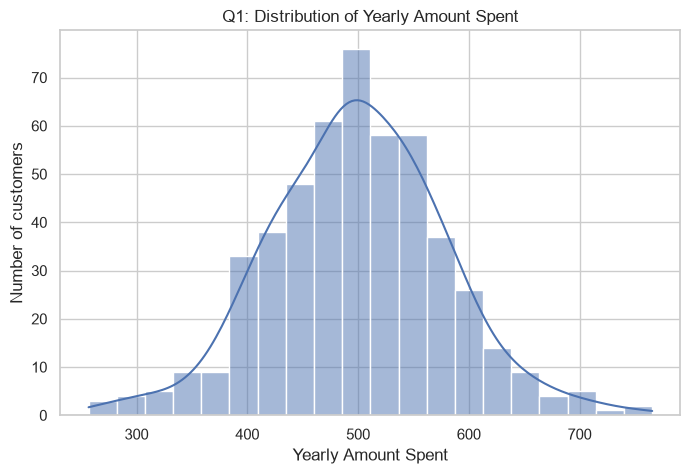

Answer: Yearly spending is approximately symmetric. The typical (median) spend is 498.89, and the mean is 499.31.


In [11]:
# Q1. What is the distribution of customers' yearly amount spent?
col = "Yearly Amount Spent"
if col in df_clean.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(df_clean[col], kde=True)
    plt.title("Q1: Distribution of Yearly Amount Spent")
    plt.xlabel("Yearly Amount Spent")
    plt.ylabel("Number of customers")
    plt.show()
    mean_value = df_clean[col].mean()
    median_value = df_clean[col].median()
    skew_value = df_clean[col].skew()
    shape = "right-skewed" if skew_value > 0.5 else "left-skewed" if skew_value < -0.5 else "approximately symmetric"
    print(f"Answer: Yearly spending is {shape}. The typical (median) spend is {median_value:.2f}, and the mean is {mean_value:.2f}.")

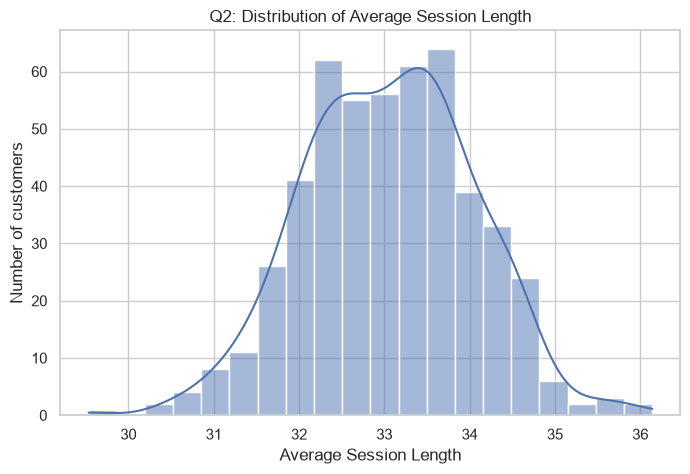

Answer: A typical customer has a session length of 33.08; the distribution is approximately symmetric (skewness = -0.03).


In [12]:
# Q2. What is the typical average session length, and is it skewed?
col = "Avg. Session Length"
if col in df_clean.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(df_clean[col], kde=True)
    plt.title("Q2: Distribution of Average Session Length")
    plt.xlabel("Average Session Length")
    plt.ylabel("Number of customers")
    plt.show()
    skew = df_clean[col].skew()
    shape = "right-skewed" if skew > 0.5 else "left-skewed" if skew < -0.5 else "approximately symmetric"
    print(f"Answer: A typical customer has a session length of {df_clean[col].median():.2f}; the distribution is {shape} (skewness = {skew:.2f}).")

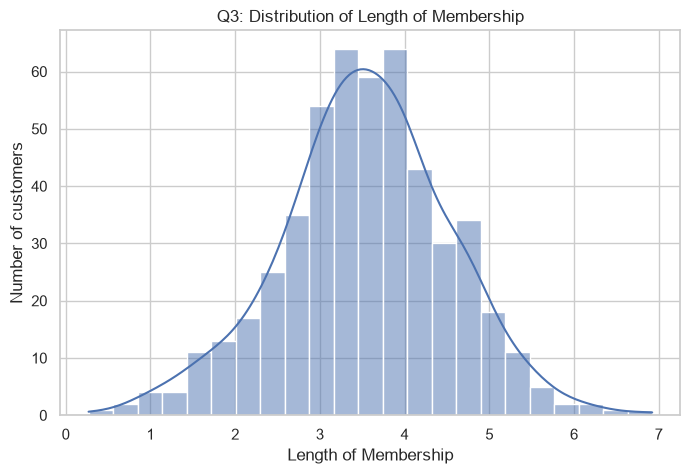

Answer: Membership length is approximately symmetric. The typical membership duration (median) is 3.53 years (dataset units).


In [13]:
# Q3. How is length of membership distributed?
col = "Length of Membership"
if col in df_clean.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(df_clean[col], kde=True)
    plt.title("Q3: Distribution of Length of Membership")
    plt.xlabel("Length of Membership")
    plt.ylabel("Number of customers")
    plt.show()
    median_value = df_clean[col].median()
    skew = df_clean[col].skew()
    shape = "right-skewed" if skew > 0.5 else "left-skewed" if skew < -0.5 else "approximately symmetric"
    print(f"Answer: Membership length is {shape}. The typical membership duration (median) is {median_value:.2f} years (dataset units).")

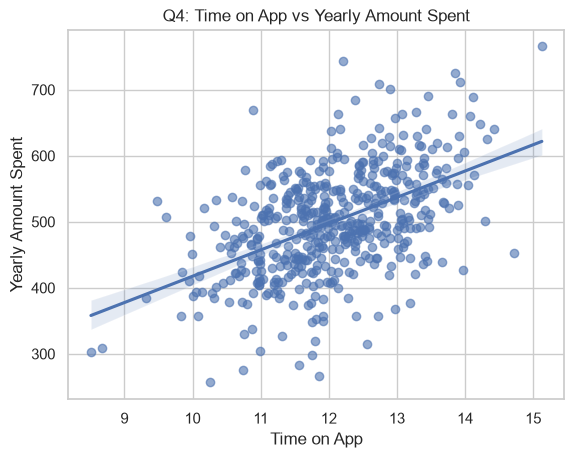

Answer: Time on the app has a moderate positive linear association with yearly spending (Pearson r = 0.499). This describes an association, not cause and effect.


In [14]:
# Q4. Is time spent on the app related to yearly amount spent?
x_col, y_col = "Time on App", "Yearly Amount Spent"
if {x_col, y_col}.issubset(df_clean.columns):
    r = df_clean[x_col].corr(df_clean[y_col])
    sns.regplot(data=df_clean, x=x_col, y=y_col, scatter_kws={"alpha": 0.6})
    plt.title("Q4: Time on App vs Yearly Amount Spent")
    plt.xlabel("Time on App")
    plt.ylabel("Yearly Amount Spent")
    plt.show()
    print(f"Answer: Time on the app has {describe_correlation(r)} with yearly spending (Pearson r = {r:.3f}). This describes an association, not cause and effect.")

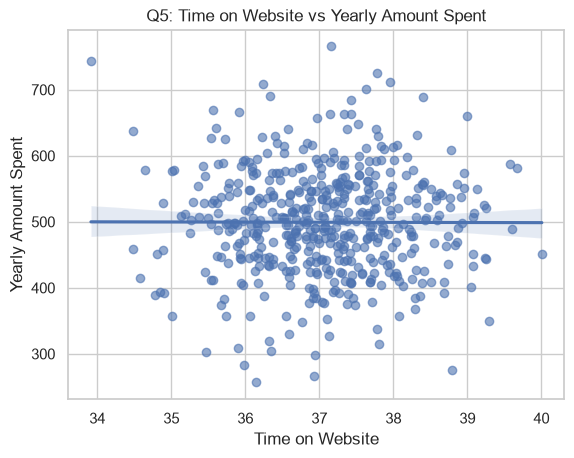

Answer: Time on the website has little to no linear association with yearly spending (Pearson r = -0.003). This describes an association, not cause and effect.


In [15]:
# Q5. Is time spent on the website related to yearly amount spent?
x_col, y_col = "Time on Website", "Yearly Amount Spent"
if {x_col, y_col}.issubset(df_clean.columns):
    r = df_clean[x_col].corr(df_clean[y_col])
    sns.regplot(data=df_clean, x=x_col, y=y_col, scatter_kws={"alpha": 0.6})
    plt.title("Q5: Time on Website vs Yearly Amount Spent")
    plt.xlabel("Time on Website")
    plt.ylabel("Yearly Amount Spent")
    plt.show()
    print(f"Answer: Time on the website has {describe_correlation(r)} with yearly spending (Pearson r = {r:.3f}). This describes an association, not cause and effect.")

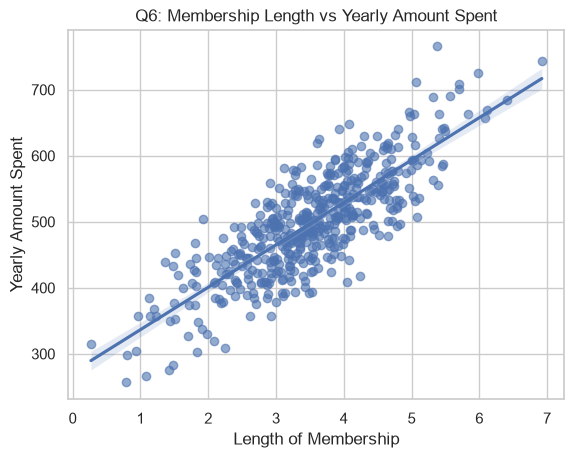

Answer: Membership length has a strong positive linear association with yearly spending (Pearson r = 0.809). This describes an association, not cause and effect.


In [16]:
# Q6. Is length of membership related to yearly amount spent?
x_col, y_col = "Length of Membership", "Yearly Amount Spent"
if {x_col, y_col}.issubset(df_clean.columns):
    r = df_clean[x_col].corr(df_clean[y_col])
    sns.regplot(data=df_clean, x=x_col, y=y_col, scatter_kws={"alpha": 0.6})
    plt.title("Q6: Membership Length vs Yearly Amount Spent")
    plt.xlabel("Length of Membership")
    plt.ylabel("Yearly Amount Spent")
    plt.show()
    print(f"Answer: Membership length has {describe_correlation(r)} with yearly spending (Pearson r = {r:.3f}). This describes an association, not cause and effect.")

In [17]:
# Q7. Which channel has the stronger relationship with yearly spending?
if {"Time on App", "Time on Website", "Yearly Amount Spent"}.issubset(df_clean.columns):
    app_r = df_clean["Time on App"].corr(df_clean["Yearly Amount Spent"])
    website_r = df_clean["Time on Website"].corr(df_clean["Yearly Amount Spent"])
    channel_results = pd.DataFrame({
        "Channel": ["Mobile App", "Website"],
        "Correlation": [app_r, website_r],
        "Absolute correlation": [abs(app_r), abs(website_r)]
    }).sort_values("Absolute correlation", ascending=False)
    display(channel_results)
    if np.isclose(abs(app_r), abs(website_r)):
        comparison_text = "App time and website time have similarly strong linear associations with yearly spending."
    else:
        stronger = channel_results.iloc[0]
        comparison_text = (
            f"{stronger['Channel']} time has the stronger linear association "
            f"(r = {stronger['Correlation']:.3f}) than the other channel."
        )
    print(f"Answer: {comparison_text} More time on a channel is associated with yearly spending, but this does not show that channel use causes spending to rise.")

,Channel,Correlation,Absolute correlation
0,Mobile App,0.499328,0.499328
1,Website,-0.002641,0.002641


Answer: Mobile App time has the stronger linear association (r = 0.499) than the other channel. More time on a channel is associated with yearly spending, but this does not show that channel use causes spending to rise.


In [18]:
# Q8. Who are the 10 highest-spending customers?
if "Yearly Amount Spent" in df_clean.columns:
    top_customers = df_clean.nlargest(10, "Yearly Amount Spent").copy()
    top_customers.insert(0, "Customer ID", [f"Customer {rank:03d}" for rank in range(1, len(top_customers) + 1)])
    safe_columns = [c for c in ["Customer ID", "Avg. Session Length", "Time on App",
                                "Time on Website", "Length of Membership", "Yearly Amount Spent"]
                    if c in top_customers.columns]
    display(top_customers[safe_columns])
    print(f"Answer: The table lists the {len(top_customers)} highest-spending records, ordered from highest to lowest. Customer IDs are temporary labels for this table; no email or address is shown.")

,Customer ID,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
65,Customer 001,34.374258,15.126994,37.157624,5.377594,765.518462
157,Customer 002,34.603311,12.207298,33.913847,6.922689,744.221867
50,Customer 003,33.256335,13.858062,37.780265,5.976768,725.584814
205,Customer 004,34.967610,13.919494,37.952013,5.066697,712.396327
368,Customer 005,34.385820,12.729720,36.232110,5.705941,708.935185
24,Customer 006,34.507551,12.893670,37.635756,5.705154,700.917092
305,Customer 007,33.302672,13.459222,36.339521,5.566385,689.787604
464,Customer 008,32.533240,14.121784,38.406329,5.320094,689.235700
151,Customer 009,32.887105,12.387184,37.431159,6.401229,684.163431
396,Customer 010,35.742670,10.889828,35.565436,6.115199,669.987141


Answer: The table lists the 10 highest-spending records, ordered from highest to lowest. Customer IDs are temporary labels for this table; no email or address is shown.


## Step 8 — Conclusion

The six-line conclusion below is generated from the cleaned dataset and summarizes the measured distributions and relationships. Correlations describe associations, not causes.

In [19]:
spending = df_clean["Yearly Amount Spent"]
session = df_clean["Avg. Session Length"]
membership = df_clean["Length of Membership"]
app_r = df_clean["Time on App"].corr(spending)
website_r = df_clean["Time on Website"].corr(spending)
membership_r = membership.corr(spending)
spending_skew = spending.skew()
spending_shape = "right-skewed" if spending_skew > 0.5 else "left-skewed" if spending_skew < -0.5 else "approximately symmetric"
stronger_channel = "mobile app" if abs(app_r) > abs(website_r) else "website" if abs(website_r) > abs(app_r) else "both channels equally"

print("CONCLUSION")
print(f"1. After cleaning, the analysis includes {len(df_clean):,} customer records.")
print(f"2. Yearly spending is {spending_shape}; the median is {spending.median():.2f} and the mean is {spending.mean():.2f}.")
print(f"3. The typical average session length is {session.median():.2f} (median), and the session distribution is {'right-skewed' if session.skew() > 0.5 else 'left-skewed' if session.skew() < -0.5 else 'approximately symmetric'}.")
print(f"4. The typical membership duration is {membership.median():.2f} dataset time units (median); its correlation with yearly spending is {membership_r:.3f} ({describe_correlation(membership_r)}).")
print(f"5. App time has a Pearson correlation of {app_r:.3f} with spending; website time has a correlation of {website_r:.3f}.")
recommendation = "Test a membership-retention initiative and measure its effect on spending" if membership_r >= 0.4 else "Run a controlled test based on the strongest observed customer-spending relationship"
print(f"6. Recommendation: {recommendation}; correlations describe association, so evaluate impact experimentally before claiming causation.")

CONCLUSION
1. After cleaning, the analysis includes 500 customer records.
2. Yearly spending is approximately symmetric; the median is 498.89 and the mean is 499.31.
3. The typical average session length is 33.08 (median), and the session distribution is approximately symmetric.
4. The typical membership duration is 3.53 dataset time units (median); its correlation with yearly spending is 0.809 (a strong positive linear association).
5. App time has a Pearson correlation of 0.499 with spending; website time has a correlation of -0.003.
6. Recommendation: Test a membership-retention initiative and measure its effect on spending; correlations describe association, so evaluate impact experimentally before claiming causation.


### Final submission checklist

- [ ] Notebook runs from top to bottom without errors.
- [ ] CSV filename is exactly `ecommerce_customers.csv`.
- [ ] CSV and notebook are in the same project folder.
- [ ] Every graph has a title and axis labels.
- [ ] Each analysis question has a graph/table and a written answer.
- [ ] Conclusion contains 5–6 lines based on actual outputs.
- [ ] Save the notebook after running all cells.

**Data privacy:** Do not publish customer email addresses or full addresses in screenshots or dashboard tables.